# Customer Segmentation on Online Retail II — K-Means and Agglomerative Clustering
**Course:** 23CSE301 Machine Learning (Capstone, Clustering Track) · **Algorithms:** K-Means (+ preprocessing), Agglomerative Hierarchical

**Pipeline.** Load → audit → clean → customer-level feature engineering (RFM+) → EDA → outlier handling & scaling → **K-Means** (Elbow, Silhouette per k, final model) → **Agglomerative** (linkage comparison, dendrogram, final model) → metrics (Silhouette, Davies-Bouldin, Calinski-Harabasz) → PCA / t-SNE visualisation → cluster profiling → comparison.

> Sources / AI-use note: code scaffolding assisted by Claude (Anthropic); analysis, feature decisions and interpretation are the team's own.

## 0. Setup

In [1]:
import os, warnings
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.dpi"] = 110

# ---- paths (works whether the notebook is run from /notebooks or repo root) ----
ROOT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
DATA_DIR, RESULTS_DIR, MODELS_DIR = ROOT/"data", ROOT/"results", ROOT/"models"
for d in (DATA_DIR, RESULTS_DIR, MODELS_DIR): d.mkdir(exist_ok=True)

## 1. Dataset loading & audit
The data comes from Kaggle (**mashlyn/online-retail-ii-uci**, a single CSV, ~1.07M rows). If `data/online_retail_II.csv` is missing, the notebook downloads it with `kagglehub` (the file is git-ignored, so the repo stays small). A local two-sheet `.xlsx` is also supported and cached to CSV.

In [2]:
KAGGLE_SLUG = "mashlyn/online-retail-ii-uci"   # Kaggle: Online Retail II UCI
COLUMN_ALIASES = {"Customer ID": "CustomerID", "InvoiceNo": "Invoice", "UnitPrice": "Price"}

def download_from_kaggle(data_dir: Path) -> Path:
    """Download the dataset from Kaggle with kagglehub and copy the CSV into data/."""
    import shutil, kagglehub
    src_dir = Path(kagglehub.dataset_download(KAGGLE_SLUG))
    src = next(src_dir.rglob("*.csv"))
    dest = data_dir / "online_retail_II.csv"
    shutil.copy(src, dest)
    return dest

def load_data(data_dir: Path) -> pd.DataFrame:
    """Load online_retail_II: local CSV -> local XLSX (cached to CSV) -> download from Kaggle."""
    csv_path = data_dir / "online_retail_II.csv"
    xlsx_path = data_dir / "online_retail_II.xlsx"
    if not csv_path.exists() and xlsx_path.exists():
        sheets = pd.read_excel(xlsx_path, sheet_name=None)          # both sheets
        pd.concat(sheets.values(), ignore_index=True).to_csv(csv_path, index=False)
    if not csv_path.exists():
        download_from_kaggle(data_dir)
    df = pd.read_csv(csv_path, parse_dates=["InvoiceDate"])
    return df.rename(columns=COLUMN_ALIASES)

raw = load_data(DATA_DIR)
df = raw.copy()
print("Shape:", df.shape)
display(df.head())

Shape: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [3]:
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "n_unique": df.nunique(),
})
display(audit)
print("Duplicate rows:", df.duplicated().sum())
print("Date range:", df["InvoiceDate"].min(), "->", df["InvoiceDate"].max())
print("Cancelled invoices (start with 'C'):", df["Invoice"].astype(str).str.startswith("C").sum())
print("Rows with Quantity <= 0:", (df["Quantity"] <= 0).sum(), "| Rows with Price <= 0:", (df["Price"] <= 0).sum())

,dtype,missing,missing_%,n_unique
Invoice,str,0,0.00,53628
StockCode,str,0,0.00,5305
Description,str,4382,0.41,5698
Quantity,int64,0,0.00,1057
InvoiceDate,datetime64[us],0,0.00,47635
Price,float64,0,0.00,2807
CustomerID,float64,243007,22.77,5942
Country,str,0,0.00,43


Duplicate rows: 34335
Date range: 2009-12-01 07:45:00 -> 2011-12-09 12:50:00
Cancelled invoices (start with 'C'): 19494
Rows with Quantity <= 0: 22950 | Rows with Price <= 0: 6207


**Audit observation:** 243,007 of 1,067,371 rows (22.8%) have no CustomerID. They can't be assigned to a customer, so they are dropped. There are 34,335 exact duplicate rows, 19,494 cancelled invoices (starting with "C"), 22,950 rows with Quantity ≤ 0 and 6,207 rows with Price ≤ 0. These are returns or adjustments, not purchases, so keeping them would give negative or meaningless spend. After cleaning, 776,577 rows and 5,852 customers remain.

## 2. Data cleaning
Each step logs how many rows it removes so every decision is justified and traceable.

| Step | Why |
|---|---|
| Drop rows with missing `CustomerID` | Segmentation is per customer; anonymous rows cannot be assigned to anyone. |
| Drop duplicate rows | Exact repeats are data-entry/export duplicates. |
| Drop cancellations (`Invoice` starts with `C`) and `Quantity <= 0` | Returns/cancellations are not purchases; keeping them gives negative spend. |
| Drop `Price <= 0` | Free items/adjustments carry no purchase-intent signal. |
| Keep only product stock codes (5 digits + optional letters) | Removes non-product codes such as POST, DOT, BANK CHARGES, AMAZONFEE, ADJUST. |

In [4]:
log = []
def step(name, frame):
    log.append({"step": name, "rows_remaining": len(frame)})
    return frame

df = step("raw", df)
df = step("drop missing CustomerID", df.dropna(subset=["CustomerID"]))
df = step("drop duplicates", df.drop_duplicates())
df = step("drop cancellations", df[~df["Invoice"].astype(str).str.startswith("C")])
df = step("drop Quantity <= 0", df[df["Quantity"] > 0])
df = step("drop Price <= 0", df[df["Price"] > 0])
df = step("keep product stock codes", df[df["StockCode"].astype(str).str.match(r"^\d{5}")])
df["CustomerID"] = df["CustomerID"].astype(int)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

cleaning_log = pd.DataFrame(log)
cleaning_log["removed"] = (-cleaning_log["rows_remaining"].diff()).fillna(0).astype(int)
display(cleaning_log)
print("Customers remaining:", df["CustomerID"].nunique())

,step,rows_remaining,removed
0,raw,1067371,0
1,drop missing CustomerID,824364,243007
2,drop duplicates,797885,26479
3,drop cancellations,779495,18390
4,drop Quantity <= 0,779495,0
5,drop Price <= 0,779425,70
6,keep product stock codes,776577,2848


Customers remaining: 5852


## 3. Feature engineering — customer-level RFM+
K-Means needs one row per **customer**, not per line item. We build the classic RFM features plus two behavioural extras.

| Feature | Definition | Why it may help clustering |
|---|---|---|
| `Recency` | Days between the customer's last purchase and a snapshot date (max date + 1 day) | Separates active from lapsed customers |
| `Frequency` | Number of distinct invoices | Separates one-off from loyal buyers |
| `Monetary` | Total spend (Quantity × Price) | Separates high-value from low-value customers |
| `AvgBasketValue` | Monetary / Frequency | Separates large-basket (wholesale-like) from small-basket buyers with the same total spend |
| `UniqueProducts` | Number of distinct StockCodes bought | Captures breadth of purchasing, which RFM ignores |

In [5]:
def build_customer_features(frame: pd.DataFrame) -> pd.DataFrame:
    frame = frame.assign(TotalPrice=frame["Quantity"] * frame["Price"])
    snapshot = frame["InvoiceDate"].max() + pd.Timedelta(days=1)
    g = frame.groupby("CustomerID")
    feats = pd.DataFrame({
        "Recency":        (snapshot - g["InvoiceDate"].max()).dt.days,
        "Frequency":      g["Invoice"].nunique(),
        "Monetary":       g["TotalPrice"].sum(),
        "UniqueProducts": g["StockCode"].nunique(),
    })
    feats["AvgBasketValue"] = feats["Monetary"] / feats["Frequency"]
    return feats[["Recency", "Frequency", "Monetary", "AvgBasketValue", "UniqueProducts"]]

customers = build_customer_features(df)
print("Customer table:", customers.shape)
display(customers.describe().T.round(2))

Customer table: (5852, 5)


,count,mean,std,min,25%,50%,75%,max
Recency,5852.0,200.20,208.51,1.00,25.00,95.00,379.00,739.00
Frequency,5852.0,6.25,12.75,1.00,1.00,3.00,7.00,373.00
Monetary,5852.0,2916.71,14306.85,2.95,339.58,856.02,2241.03,580987.04
AvgBasketValue,5852.0,384.40,1254.73,2.95,176.14,277.87,410.56,84236.25
UniqueProducts,5852.0,82.19,116.49,1.00,19.00,45.00,103.00,2546.00


## 4. EDA on the engineered features

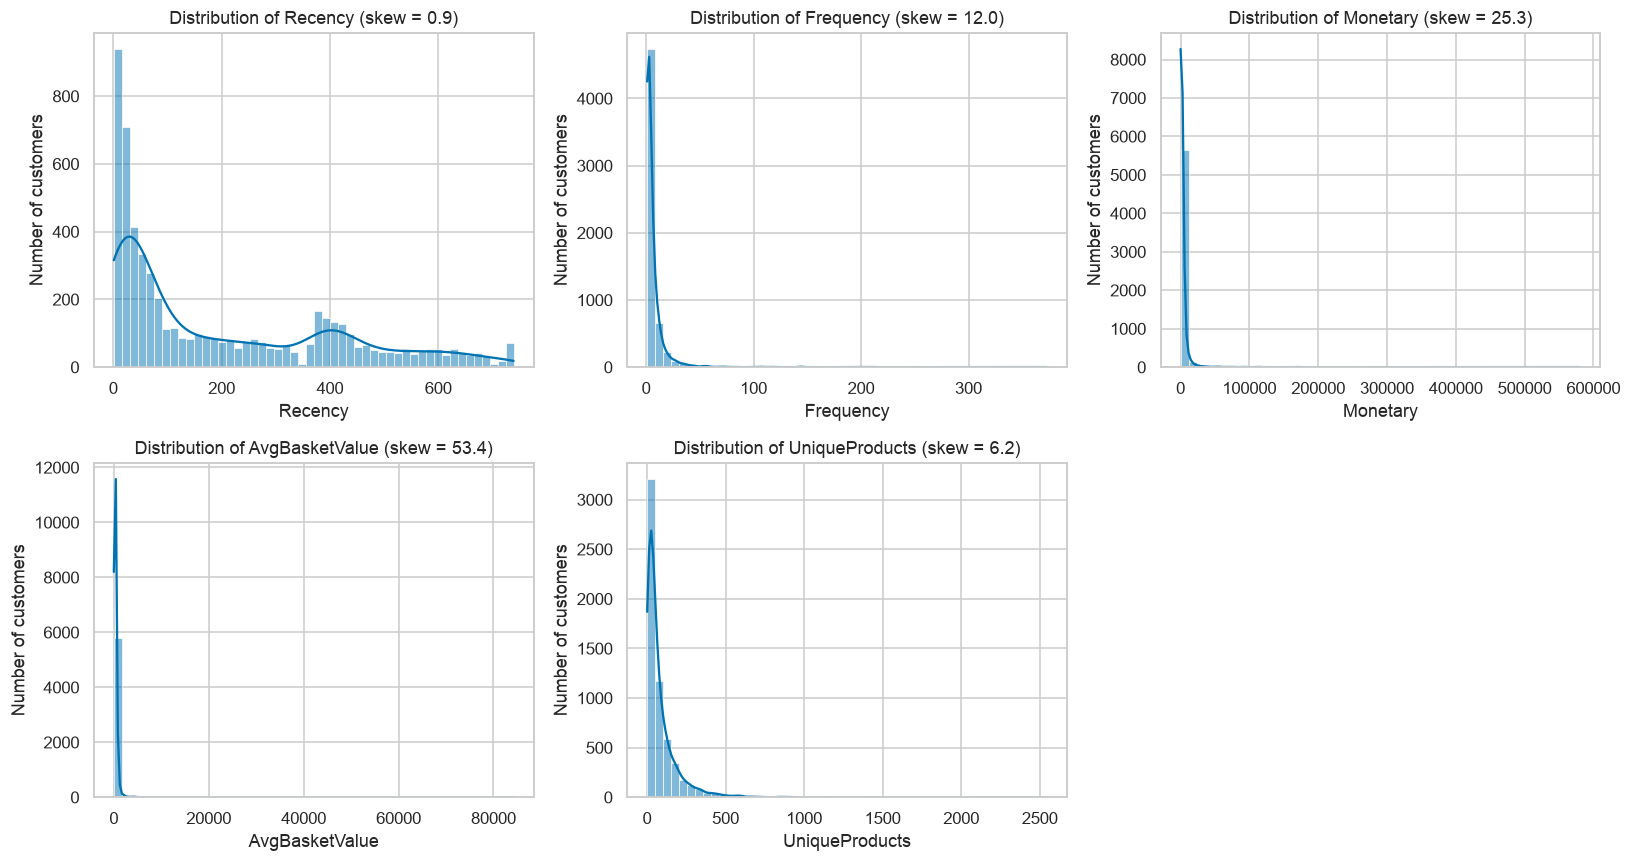

In [6]:
FEATURES = list(customers.columns)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.histplot(customers[col], bins=50, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col} (skew = {customers[col].skew():.1f})")
    ax.set_xlabel(col); ax.set_ylabel("Number of customers")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

**Observation:** Recency is only mildly right-skewed (skew 0.9). It has two peaks: one near 0–50 days (recently active customers) and a smaller one around 400 days (customers who last bought about a year before the snapshot date). The other four features are extremely right-skewed: Frequency (12.0), Monetary (25.3), AvgBasketValue (53.4) and UniqueProducts (6.2). Most customers have low values, and a few wholesale-type customers have values far larger than the rest, such as Monetary up to about £600k. K-Means uses Euclidean distance, so these extreme values would pull centroids toward them and dominate the clustering. This is why we apply winsorising, a log transform and standardisation before clustering.

Why this matters: K-Means works by measuring distances, so a handful of huge values can distort everything.

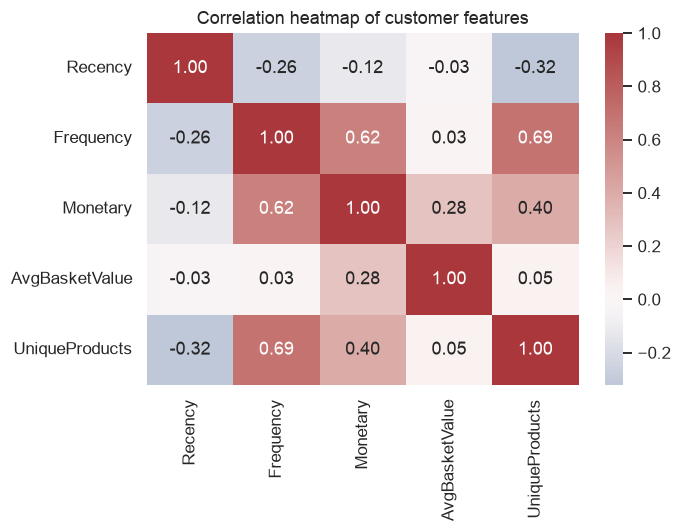

In [7]:
plt.figure(figsize=(6.5, 5))
sns.heatmap(customers.corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Correlation heatmap of customer features"); plt.tight_layout(); plt.show()

**Observation:** Frequency, Monetary and UniqueProducts are moderately to strongly correlated (Frequency–UniqueProducts 0.69, Frequency–Monetary 0.62, Monetary–UniqueProducts 0.40). Customers who order often also tend to spend more and buy a wider range of products. Recency is weakly negatively correlated with Frequency (−0.26) and UniqueProducts (−0.32), so recent customers tend to be more engaged. AvgBasketValue is almost uncorrelated with Recency, Frequency and UniqueProducts (all about 0.03–0.05), so it adds information the others lack. No pair is above 0.7, so we kept all five features. Because three features overlap, they act like one “customer value/engagement” direction, and we expect K-Means and PCA to be dominated by it.

Why this matters: correlated features count extra in distance calculations, and PCA will squeeze them into one component.

## 5. Outlier handling & scaling
* **Winsorise** each feature at its 1st/99th percentile — a handful of wholesale buyers spend 100× the median and would otherwise capture whole clusters. We cap rather than delete so no customer is lost.
* **`log1p`** transform to reduce the heavy right-skew (K-Means assumes roughly spherical, similarly scaled clusters).
* **`StandardScaler`** so no feature dominates Euclidean distance (Monetary is in £thousands, Recency in days).

> Note on leakage: the guideline asks for scalers fitted on the training set only. Clustering has **no train/test split** (unsupervised, all customers are clustered), so the scaler is fitted on the full customer table.

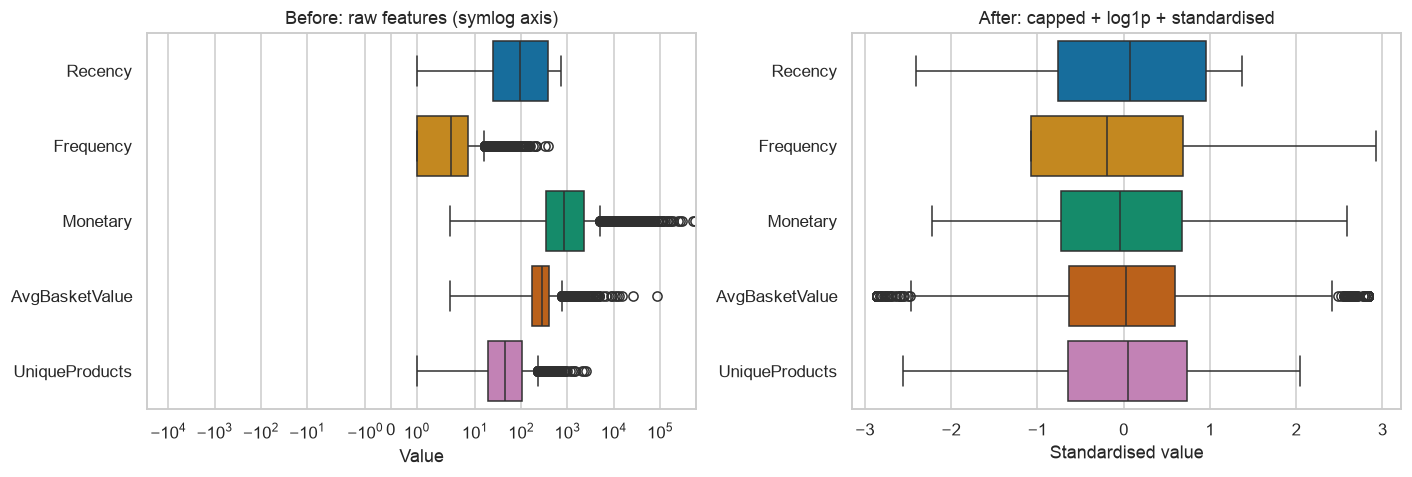

Skew before: {'Recency': 0.89, 'Frequency': 12.04, 'Monetary': 25.33, 'AvgBasketValue': 53.38, 'UniqueProducts': 6.22}
Skew after:  {'Recency': -0.49, 'Frequency': 0.82, 'Monetary': 0.22, 'AvgBasketValue': 0.02, 'UniqueProducts': -0.3}
Saved data/customers_scaled.csv


In [8]:
def preprocess_for_clustering(feats: pd.DataFrame, lower=0.01, upper=0.99):
    lo, hi = feats.quantile(lower), feats.quantile(upper)
    capped = feats.clip(lower=lo, upper=hi, axis=1)
    logged = np.log1p(capped)
    scaler = StandardScaler()
    scaled = pd.DataFrame(scaler.fit_transform(logged), index=feats.index, columns=feats.columns)
    return scaled, scaler, capped

X_scaled, scaler, customers_capped = preprocess_for_clustering(customers)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=customers, orient="h", ax=axes[0], showfliers=True); axes[0].set_xscale("symlog")
axes[0].set_title("Before: raw features (symlog axis)"); axes[0].set_xlabel("Value")
sns.boxplot(data=X_scaled, orient="h", ax=axes[1])
axes[1].set_title("After: capped + log1p + standardised"); axes[1].set_xlabel("Standardised value")
plt.tight_layout(); plt.show()
print("Skew before:", customers.skew().round(2).to_dict())
print("Skew after: ", X_scaled.skew().round(2).to_dict())

# Shared feature matrix
X_scaled.to_csv(DATA_DIR / "customers_scaled.csv")
customers.to_csv(DATA_DIR / "customers_rfm_raw.csv")
print("Saved data/customers_scaled.csv")

## 6. K-Means clustering
### 6.1 Choosing *k* — Elbow curve (mandatory) + Silhouette / DB / CH across k

,Inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz
k,,,,
2,16826.094,0.355,1.071,4322.966
3,13281.399,0.267,1.248,3518.422
4,11391.159,0.250,1.291,3057.881
5,10113.232,0.242,1.262,2767.462
6,9172.633,0.235,1.249,2560.466
7,8449.339,0.225,1.243,2399.384
8,7870.401,0.224,1.224,2268.925
9,7407.186,0.223,1.216,2154.778
10,6995.631,0.215,1.233,2065.901


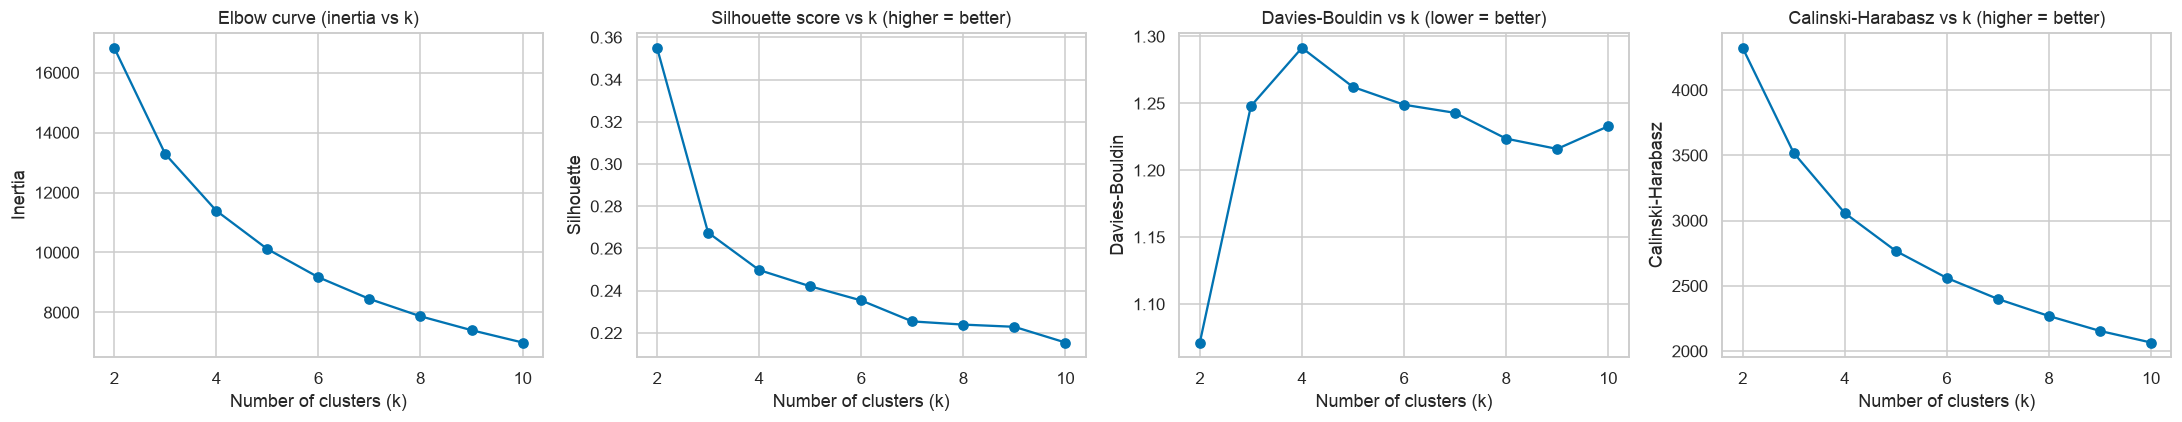

In [9]:
def evaluate_clustering(X, labels):
    return {
        "Silhouette": silhouette_score(X, labels),
        "Davies-Bouldin": davies_bouldin_score(X, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X, labels),
    }

K_RANGE = range(2, 11)
rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    rows.append({"k": k, "Inertia": km.inertia_, **evaluate_clustering(X_scaled, km.labels_)})
k_scan = pd.DataFrame(rows).set_index("k")
display(k_scan.round(3))

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (col, title) in zip(axes, [("Inertia", "Elbow curve (inertia vs k)"),
                                    ("Silhouette", "Silhouette score vs k (higher = better)"),
                                    ("Davies-Bouldin", "Davies-Bouldin vs k (lower = better)"),
                                    ("Calinski-Harabasz", "Calinski-Harabasz vs k (higher = better)")]):
    ax.plot(k_scan.index, k_scan[col], marker="o")
    ax.set_title(title); ax.set_xlabel("Number of clusters (k)"); ax.set_ylabel(col)
plt.tight_layout(); 
fig.savefig(RESULTS_DIR / "kmeans_elbow_and_metrics.png", bbox_inches="tight")
plt.show()

**Observation / justification for *k*:** The elbow curve falls smoothly with no sharp bend. There is only a mild flattening around k=3–4, which suggests the data forms a continuum rather than clearly separate groups. All three metrics agree on k=2. Silhouette is highest at about 0.355, Davies-Bouldin is lowest at about 1.07, and Calinski-Harabasz is highest at about 4,300. Silhouette drops to about 0.27 at k=3 and keeps falling to about 0.22 at k=10. Davies-Bouldin is worst at k=4 (about 1.29). A silhouette of 0.355 indicates moderate cluster structure with some overlap.

**Decision: k = 2.** All three metrics (Silhouette, Davies-Bouldin, Calinski-Harabasz) are best at k=2 for K-Means. Section 10 gives independent support: the Ward dendrogram's largest merge-distance jump is the final merge into one cluster, so the tree's natural top split is into two groups. The two segments are active, high-value customers and lapsed, low-value customers. The limitation is that k=2 splits the data along one customer-value axis. k=3 or 4 would give more detailed marketing segments, but with lower scores (Silhouette 0.27 at k=3 and 0.25 at k=4), so we treat them as a possible extension.

In [10]:
# Decision from the Elbow/Silhouette/DB/CH scan above and the Ward dendrogram (section 10): k = 2.
K_FINAL = 2
print("K_FINAL =", K_FINAL)

K_FINAL = 2


### 6.2 Final K-Means model and evaluation metrics

In [11]:
kmeans = KMeans(n_clusters=K_FINAL, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
labels = kmeans.labels_
kmeans_metrics = evaluate_clustering(X_scaled, labels)

results = pd.DataFrame([{"Algorithm": "K-Means", "k": K_FINAL, **kmeans_metrics}]).set_index("Algorithm")
display(results.round(4))
results.to_csv(RESULTS_DIR / "clustering_results.csv")   
print("Saved results/clustering_results.csv")
print("Cluster sizes:\n", pd.Series(labels).value_counts().sort_index().to_string())

,k,Silhouette,Davies-Bouldin,Calinski-Harabasz
Algorithm,,,,
K-Means,2,0.355,1.0713,4322.9661


Saved results/clustering_results.csv
Cluster sizes:
 0    3231
1    2621


**Metric interpretation (K-Means, k=2):** Silhouette = 0.355 (range −1 to 1) means moderate structure: customers are on average closer to their own cluster than to the other, but the clusters overlap, as the t-SNE plot shows. Davies-Bouldin = 1.07 (lower is better; below 1 would be well separated) shows reasonable but not sharp separation. Calinski-Harabasz = 4,323 (higher is better) is only meaningful when comparing models on the same data, which we do in section 10. The clustering is stable: the ARI across 10 other random seeds is 0.998 on average, so the result isn't an accident of initialisation. The clusters have 3,231 and 2,621 customers.

In [12]:
# Stability check: do different random initialisations give the same partition? (ARI = 1 means identical)
ref = labels
aris = [adjusted_rand_score(ref, KMeans(n_clusters=K_FINAL, n_init=10, random_state=s).fit_predict(X_scaled))
        for s in range(0, 10)]
print(f"ARI vs 10 other seeds: mean = {np.mean(aris):.3f}, min = {np.min(aris):.3f}")

ARI vs 10 other seeds: mean = 0.998, min = 0.997


## 7. Cluster visualisation — PCA (mandatory) and t-SNE

Explained variance ratio: [0.64  0.189] | total = 0.829


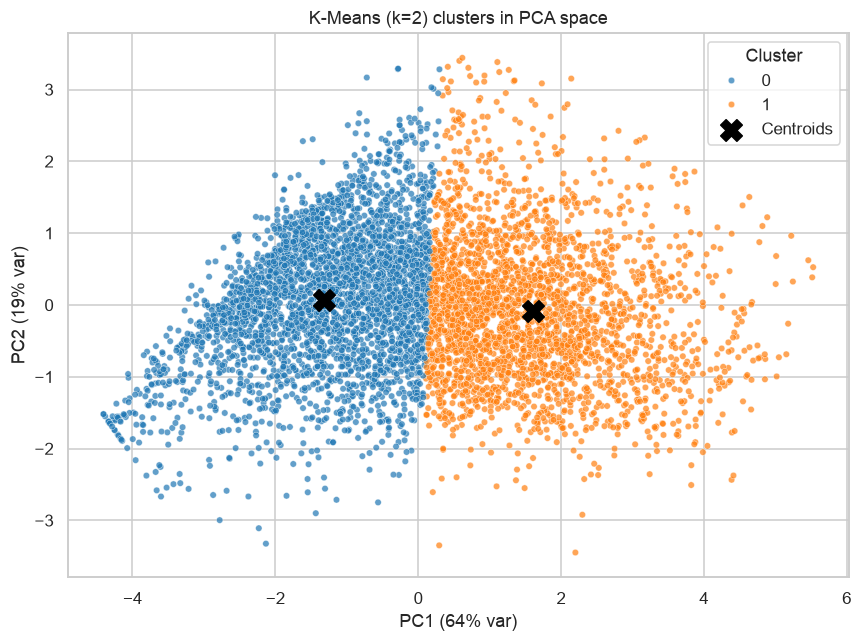

,PC1,PC2
Recency,-0.37,0.52
Frequency,0.48,-0.33
Monetary,0.54,0.15
AvgBasketValue,0.34,0.77
UniqueProducts,0.48,0.02


In [13]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(3),
      "| total =", pca.explained_variance_ratio_.sum().round(3))

fig, ax = plt.subplots(figsize=(8, 6))
sc = sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels, palette="tab10", s=18, alpha=0.7, ax=ax)
centers_pca = pca.transform(kmeans.cluster_centers_)
ax.scatter(centers_pca[:, 0], centers_pca[:, 1], c="black", marker="X", s=200, label="Centroids")
ax.set_title(f"K-Means (k={K_FINAL}) clusters in PCA space")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} var)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} var)")
ax.legend(title="Cluster"); plt.tight_layout()
fig.savefig(RESULTS_DIR / "kmeans_pca.png", bbox_inches="tight"); plt.show()

loadings = pd.DataFrame(pca.components_.T, index=X_scaled.columns, columns=["PC1", "PC2"]).round(2)
display(loadings)

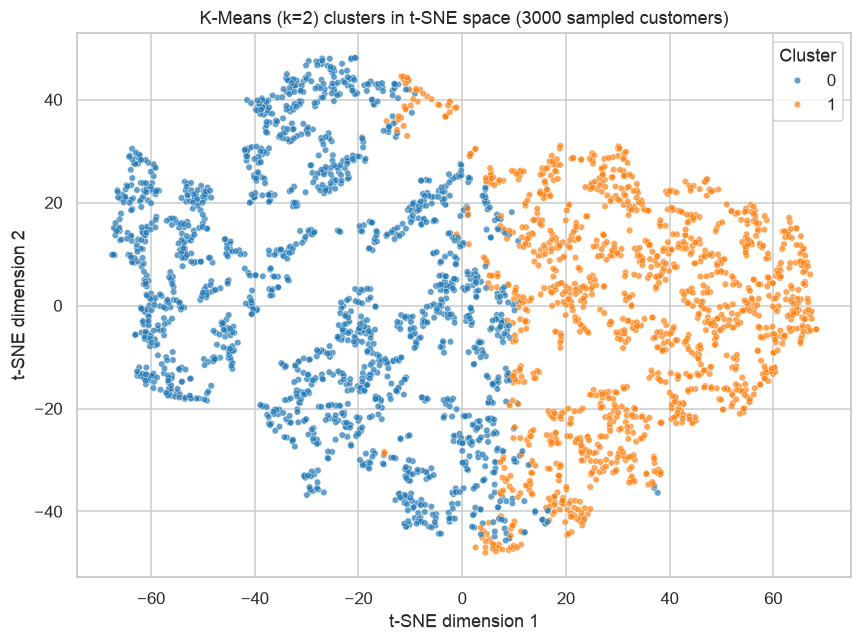

In [14]:
# t-SNE on a random sample (t-SNE is O(n^2); sampling keeps it fast)
n_sample = min(3000, len(X_scaled))
idx = np.random.RandomState(RANDOM_STATE).choice(len(X_scaled), n_sample, replace=False)
X_tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=RANDOM_STATE).fit_transform(X_scaled.iloc[idx])

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=labels[idx], palette="tab10", s=18, alpha=0.7, ax=ax)
ax.set_title(f"K-Means (k={K_FINAL}) clusters in t-SNE space ({n_sample} sampled customers)")
ax.set_xlabel("t-SNE dimension 1"); ax.set_ylabel("t-SNE dimension 2"); ax.legend(title="Cluster")
plt.tight_layout(); fig.savefig(RESULTS_DIR / "kmeans_tsne.png", bbox_inches="tight"); plt.show()

**Observation:** The two clusters occupy different regions: cluster 0 (blue) is mostly on the left and cluster 1 (orange) on the right. They touch and mix in the middle, around t-SNE dimension 1 between 0 and 15. This matches the moderate silhouette score of 0.355, since the clusters are separable but not isolated. K-Means has effectively cut one continuous cloud into two halves. Both clusters also show small local sub-blobs, which hints that finer sub-segments may exist. t-SNE is a 2-D projection of 5-D data, shown here for a 3,000-customer sample. Its distances and cluster sizes should not be over-interpreted.

Why this matters: t-SNE preserves local neighbourhoods, not global distances, so use it to see overlap, not to measure how far apart clusters are.

## 8. Cluster profiling — what does each cluster mean?

,Customers,Recency,Frequency,Monetary,AvgBasketValue,UniqueProducts,Share_%
Cluster,,,,,,,
0,3231,296.0,2.0,373.0,210.6,22.0,55.2
1,2621,30.0,7.0,2526.6,354.7,111.0,44.8


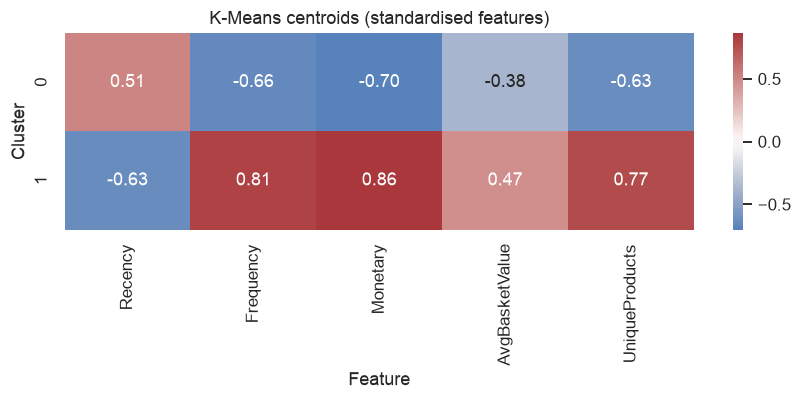

In [15]:
profile = customers.assign(Cluster=labels).groupby("Cluster").agg(
    Customers=("Recency", "size"),
    Recency=("Recency", "median"), Frequency=("Frequency", "median"),
    Monetary=("Monetary", "median"), AvgBasketValue=("AvgBasketValue", "median"),
    UniqueProducts=("UniqueProducts", "median"),
).round(1)
profile["Share_%"] = (profile["Customers"] / profile["Customers"].sum() * 100).round(1)
display(profile)

# z-score heatmap of centroids (in standardised space) – easy to read which feature defines each cluster
centroids = pd.DataFrame(kmeans.cluster_centers_, columns=X_scaled.columns)
plt.figure(figsize=(8, 0.9 * K_FINAL + 2))
sns.heatmap(centroids, annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("K-Means centroids (standardised features)"); plt.xlabel("Feature"); plt.ylabel("Cluster")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "kmeans_centroids.png", bbox_inches="tight"); plt.show()

**Segment naming (K-Means, k=2):**

| Cluster | Proposed name | Evidence (median values and centroid z-scores) | Suggested business action |
|---|---|---|---|
| 0 | Lapsed / low-value customers | High Recency (+0.51); low Frequency (−0.66), Monetary (−0.70), AvgBasketValue (−0.38) and UniqueProducts (−0.63). Medians: Recency 296 days, 2 orders, £373 spend, £211 basket, 22 products | Win-back emails, re-engagement discounts, reminders of past purchases |
| 1 | Active high-value customers | Low Recency (−0.63); high Frequency (+0.81), Monetary (+0.86), AvgBasketValue (+0.47) and UniqueProducts (+0.77). Medians: Recency 30 days, 7 orders, £2,527 spend, £355 basket, 111 products | Loyalty rewards, early access to new products, upsell and cross-sell |

These values are standardised (0 = average customer, after capping and log transform).

Cluster 0 has above-average Recency (+0.51, meaning a longer time since the last purchase) and below-average Frequency (−0.66), Monetary (−0.70), AvgBasketValue (−0.38) and UniqueProducts (−0.63). These are lapsed or low-engagement, low-value customers.
Cluster 1 has below-average Recency (−0.63, meaning recent purchases) and above-average Frequency (+0.81), Monetary (+0.86), AvgBasketValue (+0.47) and UniqueProducts (+0.77). These are active, loyal, high-value customers. It is the smaller group, with 2,621 customers (44.8%).
The clusters differ in the same “good vs weak customer” direction on all five features, which fits the correlations in the heatmap: k=2 splits the data along one customer-value axis.

## 9. Save artefacts

In [16]:
joblib.dump({"model": kmeans, "scaler": scaler, "features": FEATURES}, MODELS_DIR / "kmeans_rfm.pkl")
customers.assign(Cluster=labels).to_csv(RESULTS_DIR / "kmeans_customer_labels.csv")
print("Saved model + labels.")

Saved model + labels.


## 10. Agglomerative Hierarchical Clustering
**Why this algorithm?** K-Means required us to fix k in advance, and its elbow/silhouette showed no clear k (the data looks like a continuum). Hierarchical clustering builds the full merge tree, so the dendrogram shows how customers group at every level without choosing k first, and the nested segments are directly usable for marketing.
**Linkage comparison.** We compare Ward, complete, average and single linkage on the same standardised matrix and judge them by cophenetic correlation, the three required metrics, and cluster balance (single linkage tends to chain). We use Ward as the main model for three reasons. (1) It gives balanced clusters: its smaller cluster holds 29.6% of customers, while average and single linkage cut off a single customer (0.017%). Their high Silhouette and Davies-Bouldin values are misleading, and their Calinski-Harabasz of about 4 shows there is almost no real separation. (2) Among the balanced linkages it beats complete linkage on Silhouette (0.335 vs 0.316) and Davies-Bouldin (1.051 vs 1.122); complete is only better on Calinski-Harabasz. (3) Its variance-minimising objective is the same as K-Means', so the comparison is fair. Average linkage has the highest cophenetic correlation (0.643 vs 0.537), but its tree is dominated by one outlier chain.

### 10.1 Linkage comparison

,Cophenetic corr,Silhouette,Davies-Bouldin,Calinski-Harabasz,Smallest cluster %
Linkage,,,,,
ward,0.537,0.335,1.051,3544.533,29.631
complete,0.519,0.316,1.122,3717.494,42.191
average,0.643,0.416,0.433,4.471,0.017
single,0.454,0.421,0.449,4.158,0.017


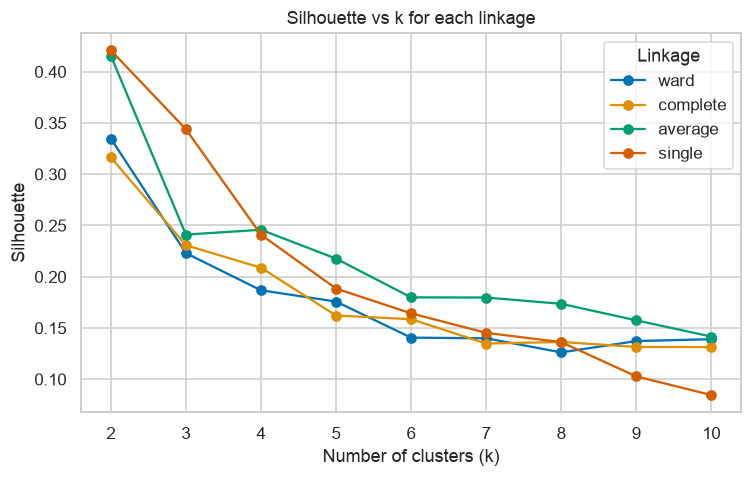

In [17]:
dist = pdist(X_scaled.values, metric="euclidean")          # condensed pairwise distances
LINKAGES = ["ward", "complete", "average", "single"]
Z = {m: linkage(dist, method=m) for m in LINKAGES}          # one tree per linkage; cut it at any k later

def cut_tree_labels(Zm, k):
    """Cut a scipy linkage tree into k clusters (labels 0..k-1)."""
    return fcluster(Zm, t=k, criterion="maxclust") - 1

def cut_height(Zm, k):
    """Distance threshold that yields exactly k clusters (for drawing the cut line)."""
    return (Zm[-(k - 1), 2] + Zm[-k, 2]) / 2

rows = []
for m in LINKAGES:
    lab = cut_tree_labels(Z[m], K_FINAL)
    rows.append({"Linkage": m,
                 "Cophenetic corr": cophenet(Z[m], dist)[0],
                 **evaluate_clustering(X_scaled, lab),
                 "Smallest cluster %": np.bincount(lab).min() / len(lab) * 100})
link_cmp = pd.DataFrame(rows).set_index("Linkage")
display(link_cmp.round(3))
link_cmp.to_csv(RESULTS_DIR / "linkage_comparison.csv")

# silhouette vs k for every linkage
fig, ax = plt.subplots(figsize=(7, 4.5))
for m in LINKAGES:
    ax.plot(list(K_RANGE), [silhouette_score(X_scaled, cut_tree_labels(Z[m], k)) for k in K_RANGE], marker="o", label=m)
ax.set_title("Silhouette vs k for each linkage"); ax.set_xlabel("Number of clusters (k)"); ax.set_ylabel("Silhouette")
ax.legend(title="Linkage"); plt.tight_layout(); fig.savefig(RESULTS_DIR / "linkage_silhouette_vs_k.png", bbox_inches="tight"); plt.show()


### 10.2 Dendrograms 

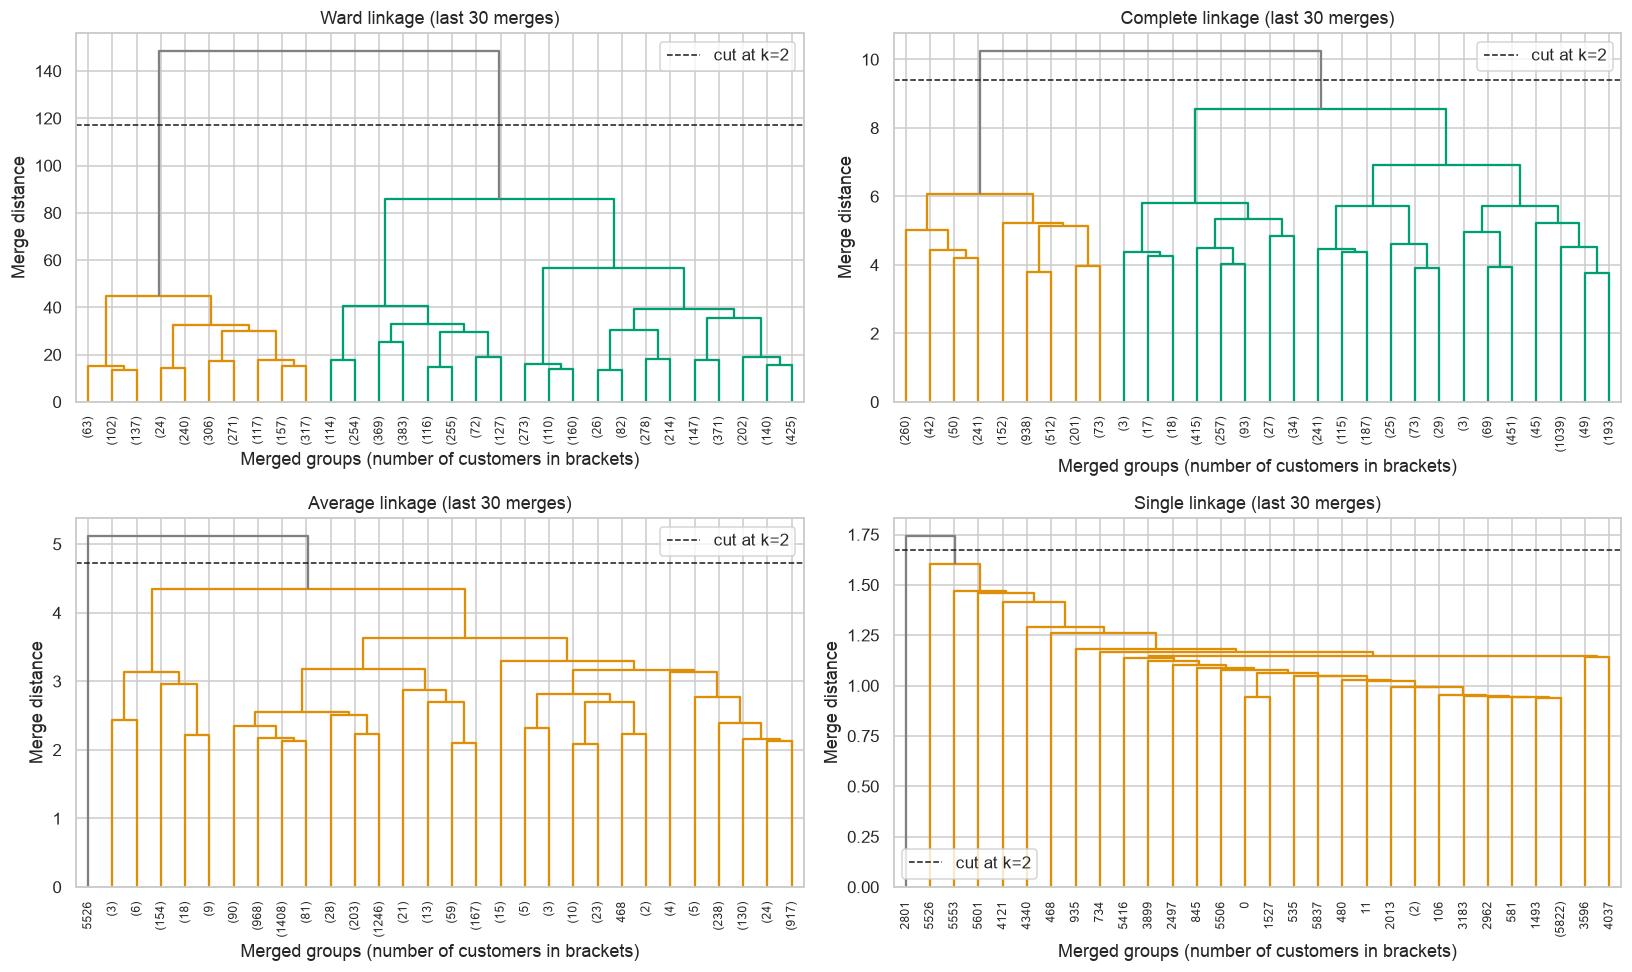

In [18]:
# ---------- 10.2 dendrograms (truncated: 5,852 leaves would be unreadable) ----------
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, m in zip(axes.ravel(), LINKAGES):
    dendrogram(Z[m], truncate_mode="lastp", p=30, ax=ax, leaf_rotation=90, leaf_font_size=8,
           color_threshold=cut_height(Z[m], K_FINAL), above_threshold_color="grey")
    ax.axhline(cut_height(Z[m], K_FINAL), ls="--", c="k", lw=1, label=f"cut at k={K_FINAL}")
    ax.set_title(f"{m.capitalize()} linkage (last 30 merges)")
    ax.set_xlabel("Merged groups (number of customers in brackets)"); ax.set_ylabel("Merge distance"); ax.legend()
plt.tight_layout(); fig.savefig(RESULTS_DIR / "dendrograms_all_linkages.png", bbox_inches="tight"); plt.show()

**Observation (linkages):** Average and single linkage put 0.017% of customers (a single customer) in the smaller cluster. Their Silhouette (0.416 and 0.421) and Davies-Bouldin (0.433 and 0.449) look best only because they separate one outlier from everyone else, and their Calinski-Harabasz of about 4 shows there is almost no real separation. Their dendrograms show the chaining effect: one long staircase, with new points joined to one growing cluster. Complete and Ward give balanced clusters (42.2% and 29.6% in the smaller one). Ward is better than complete on Silhouette (0.335 vs 0.316) and Davies-Bouldin (1.051 vs 1.122), and complete is better on Calinski-Harabasz. The dendrograms show that Ward has a clear top split into two main groups.

Why this matters: a high metric on a degenerate partition is not a good clustering, so we check cluster balance as well as the scores.

### 10.3 Merge heights:

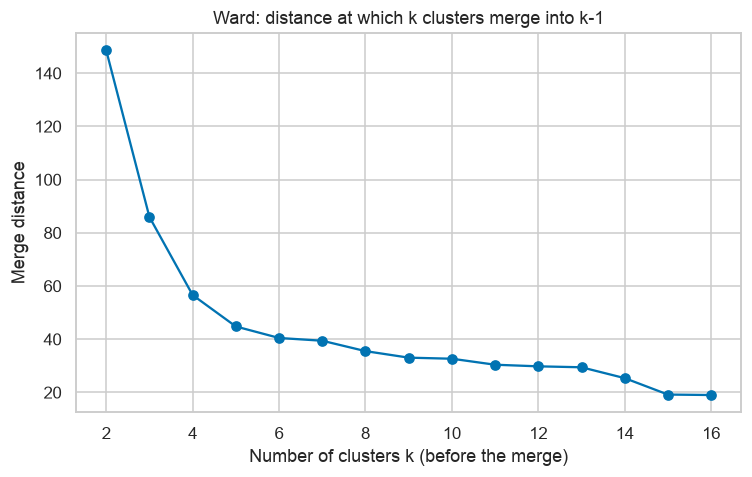

In [19]:
LINK_FINAL = "ward"        # set from link_cmp + dendrograms above
h = Z[LINK_FINAL][-15:, 2][::-1]                    # 15 largest merge distances, biggest first
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(range(2, 2 + len(h)), h, marker="o")
ax.set_title(f"{LINK_FINAL.capitalize()}: distance at which k clusters merge into k-1")
ax.set_xlabel("Number of clusters k (before the merge)"); ax.set_ylabel("Merge distance")
plt.tight_layout(); fig.savefig(RESULTS_DIR / "ward_merge_heights.png", bbox_inches="tight"); plt.show()

**Observation (merge heights):** This is the hierarchical equivalent of the elbow curve. The merge distance is largest for the last merge (about 148, when k=2 goes to 1), then falls sharply (about 86 for k=3 to 2) and flattens after about k=5. A big jump means two very different groups are being joined, so the tree's most natural split is into 2 clusters. This supports k=2 independently of the K-Means metrics. The smaller drop around k=4 suggests some finer structure, which we leave as an extension.

### 10.4 Metrics across k, Agglomerative vs K-Means

,Silhouette,Davies-Bouldin,Calinski-Harabasz
k,,,
2,0.335,1.051,3544.533
3,0.223,1.403,2966.007
4,0.187,1.304,2463.671
5,0.176,1.320,2125.838
6,0.141,1.415,1911.964
7,0.140,1.487,1786.258
8,0.126,1.402,1684.760
9,0.137,1.461,1605.631
10,0.139,1.495,1555.527


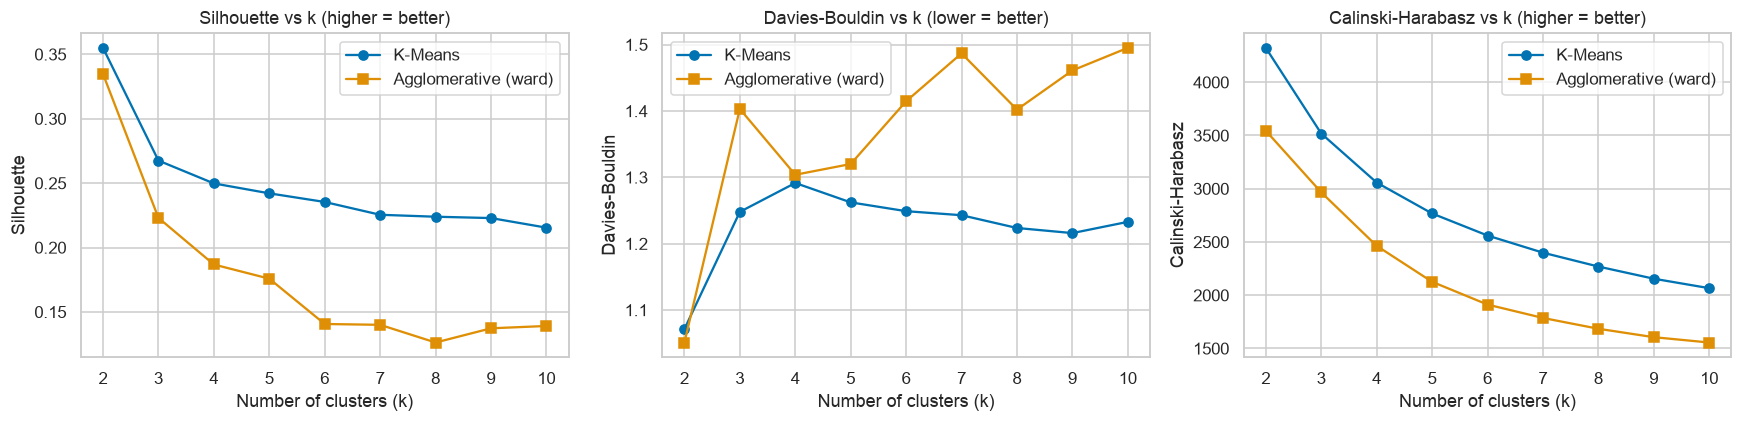

In [20]:

agg_scan = pd.DataFrame([{"k": k, **evaluate_clustering(X_scaled, cut_tree_labels(Z[LINK_FINAL], k))}
                         for k in K_RANGE]).set_index("k")
display(agg_scan.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (col, note) in zip(axes, [("Silhouette", "higher = better"),
                                  ("Davies-Bouldin", "lower = better"),
                                  ("Calinski-Harabasz", "higher = better")]):
    ax.plot(k_scan.index, k_scan[col], marker="o", label="K-Means")
    ax.plot(agg_scan.index, agg_scan[col], marker="s", label=f"Agglomerative ({LINK_FINAL})")
    ax.set_title(f"{col} vs k ({note})"); ax.set_xlabel("Number of clusters (k)"); ax.set_ylabel(col); ax.legend()
plt.tight_layout(); fig.savefig(RESULTS_DIR / "kmeans_vs_agglomerative_metrics.png", bbox_inches="tight"); plt.show()


**Observation (K-Means vs Agglomerative across k):** Both algorithms score best at k=2 on all three metrics and get worse as k grows. At k=2 they are close (Silhouette 0.355 vs 0.335, Davies-Bouldin 1.071 vs 1.051). For k≥3, K-Means scores better than Ward on all three metrics in our tables, so if the team went to 3–4 segments, K-Means would be the better-supported choice. The two curves have similar shapes, with no clear separation by algorithm.

### 10.5 Final Agglomerative model 

In [21]:
agg = AgglomerativeClustering(n_clusters=K_FINAL, linkage=LINK_FINAL).fit(X_scaled)   # Euclidean distance
agg_labels = agg.labels_
agg_metrics = evaluate_clustering(X_scaled, agg_labels)

print("Cluster sizes:\n", pd.Series(agg_labels).value_counts().sort_index().to_string())
print("Sanity check, sklearn vs scipy cut (ARI, should be 1.0):",
      round(adjusted_rand_score(agg_labels, cut_tree_labels(Z[LINK_FINAL], K_FINAL)), 3))
print("Agreement with K-Means (ARI):", round(adjusted_rand_score(labels, agg_labels), 3))
display(pd.crosstab(labels, agg_labels, rownames=["K-Means"], colnames=["Agglomerative"]))

all_results = pd.concat([results,
                         pd.DataFrame([{"Algorithm": f"Agglomerative ({LINK_FINAL})", "k": K_FINAL, **agg_metrics}]).set_index("Algorithm")])
display(all_results.round(4))
all_results.to_csv(RESULTS_DIR / "clustering_results.csv")      # final table: both algorithms

Cluster sizes:
 0    4118
1    1734
Sanity check, sklearn vs scipy cut (ARI, should be 1.0): 1.0
Agreement with K-Means (ARI): 0.479


Agglomerative,0,1
K-Means,,
0,3225,6
1,893,1728


,k,Silhouette,Davies-Bouldin,Calinski-Harabasz
Algorithm,,,,
K-Means,2,0.3550,1.0713,4322.9661
Agglomerative (ward),2,0.3347,1.0510,3544.5329


**Result (k=2):** Ward gives clusters of 4,118 (70.4%) and 1,734 (29.6%). K-Means gave 3,231 (55.2%) and 2,621 (44.8%). The ARI between them is 0.479, so they only partly agree. The crosstab shows that almost all of Ward's active cluster (1,728 of 1,734) sits inside K-Means' active cluster, but 893 customers K-Means calls active are in Ward's lapsed/low-value cluster. Both algorithms find the same customer-value axis and differ only in where they cut it: Ward's active group is stricter. This is consistent with the continuum we saw in the elbow curve, because with no sharp natural break the exact boundary depends on the algorithm.

## 11. PCA  + t-SNE 

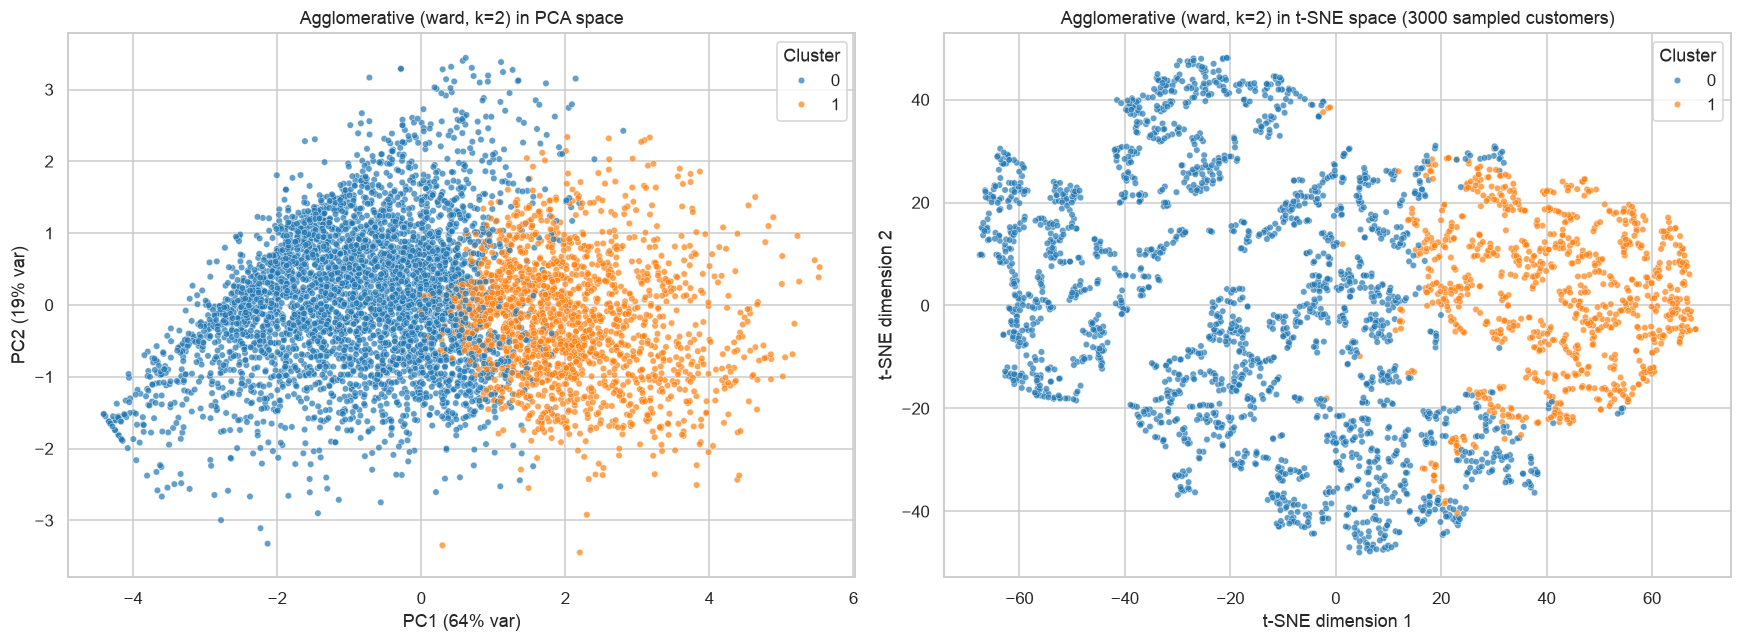

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=agg_labels, palette="tab10", s=18, alpha=0.7, ax=axes[0])
axes[0].set_title(f"Agglomerative ({LINK_FINAL}, k={K_FINAL}) in PCA space")
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} var)"); axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} var)")
axes[0].legend(title="Cluster")
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=agg_labels[idx], palette="tab10", s=18, alpha=0.7, ax=axes[1])
axes[1].set_title(f"Agglomerative ({LINK_FINAL}, k={K_FINAL}) in t-SNE space ({len(idx)} sampled customers)")
axes[1].set_xlabel("t-SNE dimension 1"); axes[1].set_ylabel("t-SNE dimension 2"); axes[1].legend(title="Cluster")
plt.tight_layout(); fig.savefig(RESULTS_DIR / "agglomerative_pca_tsne.png", bbox_inches="tight"); plt.show()

**Observation (visualisation):** In PCA space the two clusters are separated mainly along PC1 (64% of variance, the customer-value direction), with a region of overlap in the middle. In t-SNE the active cluster (orange) forms one connected region on the right, and the lapsed cluster (blue) is spread across many local groups. The overlap matches the moderate Silhouette of 0.335. PCA and t-SNE show only 2 dimensions of the 5-D data, so distances and cluster sizes in the plots shouldn't be over-interpreted.

## 12. Profiling

,Customers,Recency,Frequency,Monetary,AvgBasketValue,UniqueProducts,Share_%
Cluster,,,,,,,
0,4118,225.0,2.0,498.7,234.7,28.0,70.4
1,1734,29.0,10.0,3625.6,360.5,144.0,29.6


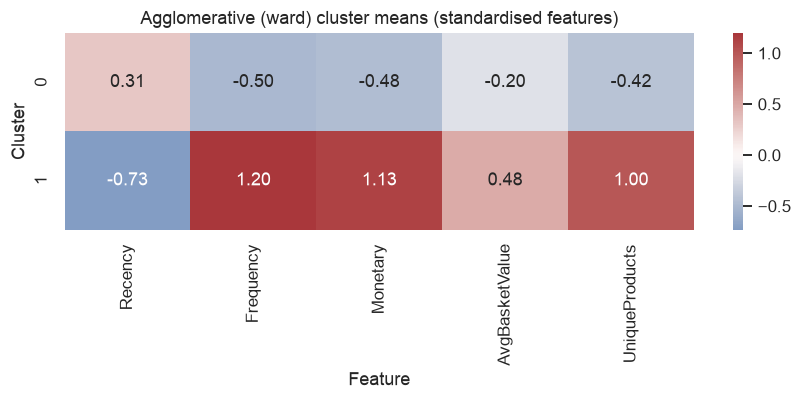

In [23]:
agg_profile = customers.assign(Cluster=agg_labels).groupby("Cluster").agg(
    Customers=("Recency", "size"),
    Recency=("Recency", "median"), Frequency=("Frequency", "median"),
    Monetary=("Monetary", "median"), AvgBasketValue=("AvgBasketValue", "median"),
    UniqueProducts=("UniqueProducts", "median")).round(1)
agg_profile["Share_%"] = (agg_profile["Customers"] / agg_profile["Customers"].sum() * 100).round(1)
display(agg_profile)

agg_centroids = X_scaled.groupby(agg_labels).mean()          # mean of standardised features per cluster
plt.figure(figsize=(8, 0.9 * K_FINAL + 2))
sns.heatmap(agg_centroids, annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title(f"Agglomerative ({LINK_FINAL}) cluster means (standardised features)"); plt.xlabel("Feature"); plt.ylabel("Cluster")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "agglomerative_centroids.png", bbox_inches="tight"); plt.show()


**Segment naming (Agglomerative, Ward, k=2):**

| Cluster | Proposed name | Evidence (medians and centroid z-scores) | Suggested business action |
|---|---|---|---|
| 0 | Lapsed / low-value customers (70.4%) | Medians: Recency 225 days, 2 orders, £499 spend, £235 basket, 28 products. z-scores: [0.31, -0.50, -0.48, -0.20, -0.42] | Win-back emails, re-engagement discounts |
| 1 | Core high-value customers (29.6%) | Medians: Recency 29 days, 10 orders, £3,626 spend, £361 basket, 144 products. z-scores: [-0.73, 1.20, 1.13, 0.48, 1.00] | Loyalty rewards, early access, upsell |

Compared with K-Means, Ward's high-value segment is smaller and stricter (10 vs 7 median orders, £3,626 vs £2,527 spend), so it targets the best customers more precisely.

## 13. Save Artifacts

In [24]:
customers.assign(Cluster=agg_labels).to_csv(RESULTS_DIR / "agglomerative_customer_labels.csv")
np.save(MODELS_DIR / f"{LINK_FINAL}_linkage_matrix.npy", Z[LINK_FINAL])
print("Saved labels + linkage matrix.")

Saved labels + linkage matrix.


## 14. Conclusion

We segmented 5,852 customers using five RFM+ features after capping, log transform and standardisation. We chose k=2 because all three metrics for K-Means and the Ward dendrogram both point to it. K-Means (Silhouette 0.355, DB 1.07, CH 4,323) and Ward Agglomerative (0.335, 1.051, 3,545) perform similarly: K-Means is better on Silhouette and CH, Ward on Davies-Bouldin. Both find the same two segments, active high-value customers and lapsed low-value customers, but they place the boundary differently (K-Means 55%/45%, Ward 70%/30%, ARI 0.479). That fits the continuum we saw in the elbow curve and t-SNE plot: customers vary smoothly along a single value axis, with no sharp natural break. Limitations: K-Means assumes roughly spherical clusters and is sensitive to scaling; hierarchical clustering needs O(n²) memory and can't undo merges; single and average linkage chain; PCA and t-SNE show only 2 of 5 dimensions; and we have only internal metrics, no ground truth. Next steps: try k=3–4 for finer marketing segments, and test other features or algorithms such as Gaussian mixtures.